# 03 - Feature Engineering and Feature Selection

Here we test feature groups and 5 new engineered features on `results/train.csv` using the same 5-fold CV splits. `test.csv` is not touched.


In [1]:
# import shared helpers and models
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from src import evaluate, preprocess

sns.set_theme(style="whitegrid")

df, all_63 = preprocess.load_train_data()
y = df["target"].to_numpy()
splits = evaluate.make_cv_splits(df)
print("train shape:", df.shape, "| features:", len(all_63))


train shape: (12378, 66) | features: 63


## 1. Feature Groups and Helper Function

We split all 63 features into 8 clear groups so we can measure how much each group helps over the core baseline.


In [2]:
# split all 63 features into topic groups
GROUPS = {
    "core": [
        "age", "sex", "education", "income_poverty_ratio", "marital_status",
        "height_cm", "weight_kg", "bmi", "waist_cm", "waist_height_ratio",
        "systolic_mean", "diastolic_mean", "pulse", "family_diabetes",
    ],
    "symptoms": [
        "nightly_urination_count_5plus", "plain_water_day1_g",
        "reported_unintentional_loss_10lb", "fatigue_frequency_2w",
        "urge_urinary_leakage", "poor_appetite_or_overeating_frequency",
        "concentration_difficulty_frequency", "sleep_problems_or_oversleep_frequency",
    ],
    "dental": [
        "self_rated_teeth_and_gums", "self_suspected_gum_disease",
        "loose_tooth_without_injury", "mouth_aching_frequency_1y", "floss_days_7d",
    ],
    "weight_history": [
        "weight_1year_ago_kg", "weight_change_1y_kg", "attempted_weight_loss_1y",
        "reported_weight_change_10y_kg", "highest_ever_weight_kg",
    ],
    "sleep": [
        "sleep_workday_hours", "daytime_sleepiness_frequency",
        "sleep_breathing_difficulty_frequency", "snoring_frequency",
    ],
    "activity_smoke_alcohol": [
        "work_activity_min_week", "leisure_activity_min_week", "transport_min_week",
        "sedentary_min_day", "smoking_status", "cigarettes_per_smoking_day",
        "smoking_inside_home", "alcohol_frequency", "drinks_per_drinking_day",
    ],
    "diet_meals": [
        "energy_kcal", "carbohydrate_g", "protein_g", "total_fat_g",
        "total_sugar_g", "fiber_g", "self_rated_diet_quality",
        "away_from_home_meals_7d", "fast_food_pizza_meals_7d",
        "ready_to_eat_foods_30d", "frozen_meals_pizza_30d",
        "sweetened_beverages_day1_g",
    ],
    "other_survey": [
        "walking_difficulty_without_equipment", "adult_food_security",
        "employment_status_last_week", "serious_vision_difficulty",
        "taste_difficulty_1y", "persistent_mouth_sensation_1y",
    ],
}

# check that all 63 features are covered with no duplicates
flat = [c for cols in GROUPS.values() for c in cols]
assert len(flat) == 63 and set(flat) == set(all_63)
for name, cols in GROUPS.items():
    print(f"{name:24s}: {len(cols)} features")


# run 5-fold CV for a given model type and feature list
def run_cv(data, cols, model_type="logreg"):
    oof = np.zeros(len(data))
    for tr, va in splits:
        X_tr, X_va = data.iloc[tr][cols], data.iloc[va][cols]
        prep = preprocess.build_preprocessor(model_type, cols)

        if model_type == "logreg":
            pipe = Pipeline([
                ("prep", prep),
                ("clf", LogisticRegression(max_iter=1000, random_state=evaluate.SEED)),
            ])
            pipe.fit(X_tr, y[tr])
            oof[va] = pipe.predict_proba(X_va)[:, 1]
        elif model_type == "rf":
            pipe = Pipeline([
                ("prep", prep),
                ("clf", RandomForestClassifier(
                    n_estimators=200, max_depth=12, min_samples_leaf=10,
                    n_jobs=-1, random_state=evaluate.SEED,
                )),
            ])
            pipe.fit(X_tr, y[tr])
            oof[va] = pipe.predict_proba(X_va)[:, 1]
        elif model_type == "catboost":
            Xt_tr = prep.fit_transform(X_tr)
            Xt_va = prep.transform(X_va)
            cat_cols = prep.named_steps["prep"].cat_cols
            clf = CatBoostClassifier(
                iterations=350, depth=6, learning_rate=0.05,
                random_seed=evaluate.SEED, verbose=0, thread_count=-1,
            )
            clf.fit(Xt_tr, y[tr], cat_features=cat_cols)
            oof[va] = clf.predict_proba(Xt_va)[:, 1]
        else:
            raise ValueError(model_type)

    _, m = evaluate.find_best_threshold(y, oof)
    return m


core                    : 14 features
symptoms                : 8 features
dental                  : 5 features
weight_history          : 5 features
sleep                   : 4 features
activity_smoke_alcohol  : 9 features
diet_meals              : 12 features
other_survey            : 6 features


## 2. Group Addition Test (Over Core Baseline)

We start with `core` (14 features) and add each other group one by one on the same 5 folds.


In [3]:
# test core alone, core + each group, and all 63 with logreg and rf
group_rows = []
core_cols = GROUPS["core"]

exp_sets = [("core", core_cols)]
for gname, gcols in GROUPS.items():
    if gname != "core":
        exp_sets.append((f"core + {gname}", core_cols + gcols))
exp_sets.append(("all_63", all_63))

for label, cols in exp_sets:
    m_lr = run_cv(df, cols, "logreg")
    m_rf = run_cv(df, cols, "rf")
    group_rows.append({
        "feature_set": label,
        "n_features": len(cols),
        "lr_auc": m_lr["roc_auc"],
        "lr_f2": m_lr["f2"],
        "rf_auc": m_rf["roc_auc"],
        "rf_f2": m_rf["f2"],
    })

group_df = pd.DataFrame(group_rows)
base_lr_auc = group_df.loc[group_df["feature_set"] == "core", "lr_auc"].iloc[0]
base_rf_auc = group_df.loc[group_df["feature_set"] == "core", "rf_auc"].iloc[0]
group_df["lr_auc_diff"] = (group_df["lr_auc"] - base_lr_auc).round(4)
group_df["rf_auc_diff"] = (group_df["rf_auc"] - base_rf_auc).round(4)
display(group_df)


,feature_set,n_features,lr_auc,lr_f2,rf_auc,rf_f2,lr_auc_diff,rf_auc_diff
0,core,14,0.7468,0.6140,0.7447,0.6029,0.0000,0.0000
1,core + symptoms,22,0.7467,0.6135,0.7439,0.6044,-0.0001,-0.0008
2,core + dental,19,0.7459,0.6100,0.7460,0.6099,-0.0009,0.0013
3,core + weight_history,19,0.7538,0.6274,0.7486,0.6103,0.0070,0.0039
4,core + sleep,18,0.7482,0.6138,0.7454,0.6096,0.0014,0.0007
5,core + activity_smoke_alcohol,23,0.7528,0.6272,0.7496,0.6179,0.0060,0.0049
6,core + diet_meals,26,0.7495,0.6193,0.7440,0.6064,0.0027,-0.0007
7,core + other_survey,20,0.7479,0.6182,0.7445,0.6123,0.0011,-0.0002
8,all_63,63,0.7610,0.6422,0.7533,0.6209,0.0142,0.0086


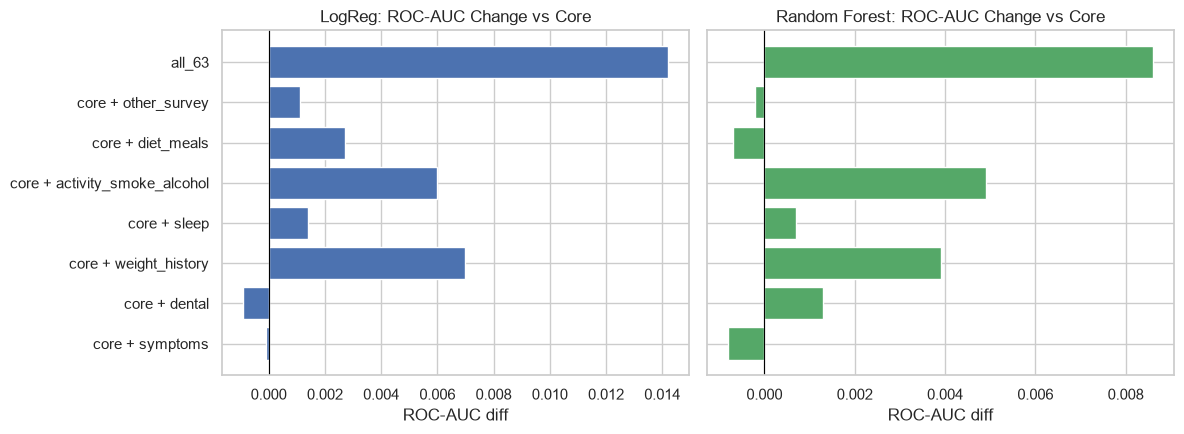

In [4]:
# plot ROC-AUC change compared to core baseline
plot_df = group_df[group_df["feature_set"] != "core"].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
axes[0].barh(plot_df["feature_set"], plot_df["lr_auc_diff"], color="#4c72b0")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("LogReg: ROC-AUC Change vs Core")
axes[0].set_xlabel("ROC-AUC diff")

axes[1].barh(plot_df["feature_set"], plot_df["rf_auc_diff"], color="#55a868")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Random Forest: ROC-AUC Change vs Core")
axes[1].set_xlabel("ROC-AUC diff")

plt.tight_layout()
plt.show()


## 3. Feature Engineering Test (5 New Candidates)

We test 5 simple domain features on top of `all_63` and only keep the ones that help CV.


In [5]:
# create 5 candidate engineered features on a copy of train data
df_fe = df.copy()
df_fe["pulse_pressure"] = df_fe["systolic_mean"] - df_fe["diastolic_mean"]
df_fe["total_activity_min_week"] = (
    df_fe["work_activity_min_week"] + df_fe["leisure_activity_min_week"] + df_fe["transport_min_week"]
)
df_fe["weight_to_highest_ratio"] = df_fe["weight_kg"] / df_fe["highest_ever_weight_kg"].where(df_fe["highest_ever_weight_kg"] > 0)
df_fe["sugar_to_carb_ratio"] = df_fe["total_sugar_g"] / df_fe["carbohydrate_g"].where(df_fe["carbohydrate_g"] > 0)

both_w = df_fe["highest_ever_weight_kg"].notna() & df_fe["weight_kg"].notna()
df_fe["highest_weight_inconsistent"] = np.where(
    both_w,
    (df_fe["highest_ever_weight_kg"] < df_fe["weight_kg"] - 2.0).astype(float),
    np.nan,
)

fe_num_cols = ["pulse_pressure", "total_activity_min_week", "weight_to_highest_ratio", "sugar_to_carb_ratio"]
fe_bin_cols = ["highest_weight_inconsistent"]
fe_all = fe_num_cols + fe_bin_cols

# register new columns so build_preprocessor knows their types
for c in fe_num_cols:
    if c not in preprocess.NUMERIC_COLS:
        preprocess.NUMERIC_COLS.append(c)
for c in fe_bin_cols:
    if c not in preprocess.BINARY_COLS:
        preprocess.BINARY_COLS.append(c)

# test each engineered feature one by one and all together
fe_rows = []
base_lr = run_cv(df_fe, all_63, "logreg")
base_rf = run_cv(df_fe, all_63, "rf")
fe_rows.append({
    "experiment": "all_63 (baseline)",
    "lr_auc": base_lr["roc_auc"], "lr_f2": base_lr["f2"],
    "rf_auc": base_rf["roc_auc"], "rf_f2": base_rf["f2"],
})

for col in fe_all:
    m_lr = run_cv(df_fe, all_63 + [col], "logreg")
    m_rf = run_cv(df_fe, all_63 + [col], "rf")
    fe_rows.append({
        "experiment": f"+ {col}",
        "lr_auc": m_lr["roc_auc"], "lr_f2": m_lr["f2"],
        "rf_auc": m_rf["roc_auc"], "rf_f2": m_rf["f2"],
    })

m_lr = run_cv(df_fe, all_63 + fe_all, "logreg")
m_rf = run_cv(df_fe, all_63 + fe_all, "rf")
fe_rows.append({
    "experiment": "+ all 5 engineered",
    "lr_auc": m_lr["roc_auc"], "lr_f2": m_lr["f2"],
    "rf_auc": m_rf["roc_auc"], "rf_f2": m_rf["f2"],
})

fe_df = pd.DataFrame(fe_rows)
fe_df["lr_auc_diff"] = (fe_df["lr_auc"] - base_lr["roc_auc"]).round(4)
fe_df["rf_auc_diff"] = (fe_df["rf_auc"] - base_rf["roc_auc"]).round(4)
display(fe_df)


,experiment,lr_auc,lr_f2,rf_auc,rf_f2,lr_auc_diff,rf_auc_diff
0,all_63 (baseline),0.7610,0.6422,0.7533,0.6209,0.0000,0.0000
1,+ pulse_pressure,0.7608,0.6424,0.7528,0.6223,-0.0002,-0.0005
2,+ total_activity_min_week,0.7610,0.6418,0.7526,0.6231,0.0000,-0.0007
3,+ weight_to_highest_ratio,0.7611,0.6415,0.7560,0.6241,0.0001,0.0027
4,+ sugar_to_carb_ratio,0.7610,0.6438,0.7530,0.6254,0.0000,-0.0003
5,+ highest_weight_inconsistent,0.7609,0.6404,0.7537,0.6228,-0.0001,0.0004
6,+ all 5 engineered,0.7609,0.6424,0.7552,0.6234,-0.0001,0.0019


## 4. Compare Main Feature Sets Across All 3 Models

Here we compare:
- `core_14`: only the 14 core clinical/demographic features
- `no_cycle_only_57`: drop the 6 cycle-only columns with >50% missing
- `all_63`: all 63 original features
- `all_63_plus_fe`: all 63 features + the engineered features that helped


In [6]:
# 6 cycle-only columns that have more than 50% missing values
high_missing_cycle_cols = {
    "daytime_sleepiness_frequency",
    "sleep_breathing_difficulty_frequency",
    "snoring_frequency",
    "loose_tooth_without_injury",
    "taste_difficulty_1y",
    "persistent_mouth_sensation_1y",
}
no_cycle_only_57 = [c for c in all_63 if c not in high_missing_cycle_cols]

# keep engineered columns that improved average ROC-AUC over baseline
helpful_fe = []
for col in fe_all:
    row = fe_df.loc[fe_df["experiment"] == f"+ {col}"].iloc[0]
    if (row["lr_auc_diff"] + row["rf_auc_diff"]) > 0:
        helpful_fe.append(col)
print("engineered features kept:", helpful_fe)

candidate_sets = {
    "core_14": GROUPS["core"],
    "no_cycle_only_57": no_cycle_only_57,
    "all_63": all_63,
    "all_63_plus_fe": all_63 + helpful_fe,
}

comp_rows = []
for model_type in ["logreg", "rf", "catboost"]:
    for set_name, cols in candidate_sets.items():
        m = run_cv(df_fe, cols, model_type)
        comp_rows.append({
            "model": model_type,
            "feature_set": set_name,
            "n_features": len(cols),
            "roc_auc": m["roc_auc"],
            "pr_auc": m["pr_auc"],
            "f2": m["f2"],
            "recall": m["recall"],
            "specificity": m["specificity"],
            "threshold": m["threshold"],
        })

comp_df = pd.DataFrame(comp_rows)
display(comp_df)


engineered features kept: ['weight_to_highest_ratio', 'highest_weight_inconsistent']


,model,feature_set,n_features,roc_auc,pr_auc,f2,recall,specificity,threshold
0,logreg,core_14,14,0.7468,0.5139,0.6140,0.6598,0.7002,0.320
1,logreg,no_cycle_only_57,57,0.7608,0.5384,0.6408,0.6928,0.7002,0.314
2,logreg,all_63,63,0.7610,0.5391,0.6422,0.6944,0.7006,0.314
3,logreg,all_63_plus_fe,65,0.7611,0.5395,0.6426,0.6950,0.7003,0.313
4,rf,core_14,14,0.7447,0.5099,0.6029,0.6456,0.7021,0.351
5,rf,no_cycle_only_57,57,0.7532,0.5312,0.6202,0.6674,0.7001,0.350
6,rf,all_63,63,0.7533,0.5300,0.6209,0.6677,0.7018,0.353
7,rf,all_63_plus_fe,65,0.7550,0.5358,0.6258,0.6739,0.7011,0.350
8,catboost,core_14,14,0.7426,0.5081,0.6031,0.6461,0.7010,0.345
9,catboost,no_cycle_only_57,57,0.7591,0.5360,0.6360,0.6865,0.7013,0.330


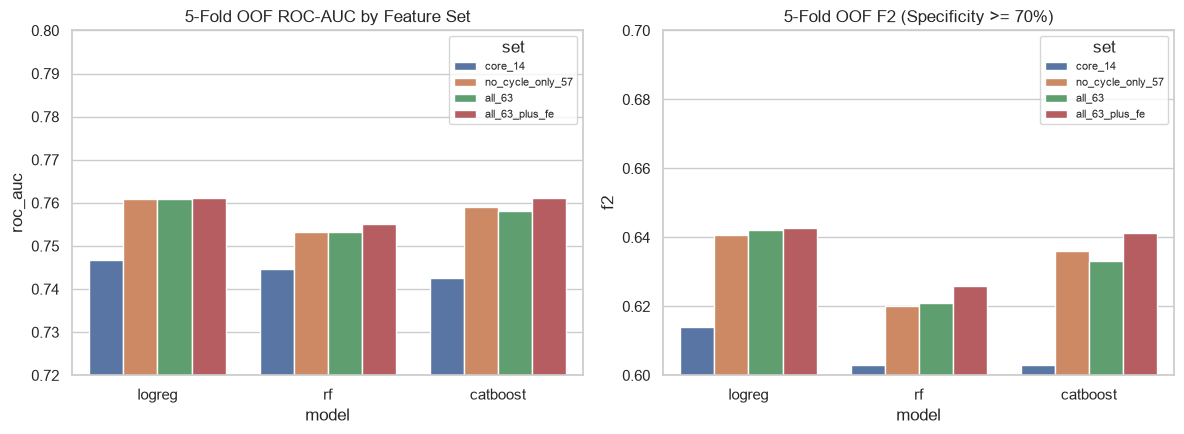

In [7]:
# plot ROC-AUC and F2 across all 3 models and candidate feature sets
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=comp_df, x="model", y="roc_auc", hue="feature_set", ax=axes[0])
axes[0].set_title("5-Fold OOF ROC-AUC by Feature Set")
axes[0].set_ylim(0.72, 0.80)
axes[0].legend(title="set", fontsize=8)

sns.barplot(data=comp_df, x="model", y="f2", hue="feature_set", ax=axes[1])
axes[1].set_title("5-Fold OOF F2 (Specificity >= 70%)")
axes[1].set_ylim(0.60, 0.70)
axes[1].legend(title="set", fontsize=8)

plt.tight_layout()
plt.show()
